In [1]:
import os
os.chdir('/Users/yaminiumarani/Desktop/rag_thesis_project')

import sys
sys.path.append('src')

from retriever import (
    baseline_retrieve,
    dynamic_weighted_retrieve,
    get_label_relevance_score,
    get_author_authority,
    make_authority_lookup,
    label_keywords
)

print("All functions imported successfully! ✅")

All functions imported successfully! ✅


In [2]:
import pandas as pd
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

# Load everything
df = pd.read_csv('data/github_issues_final.csv', low_memory=False)
model = SentenceTransformer('all-MiniLM-L6-v2')
index = faiss.read_index('data/baseline_faiss.index')
author_df = pd.read_csv('data/author_authority_scores.csv')
authority_lookup = make_authority_lookup(author_df)

# Quick test of imported functions
results = dynamic_weighted_retrieve(
    "window resize not working correctly",
    model, index, df, authority_lookup, top_k=3
)

print("Dataset:", df.shape)
print("Index:", index.ntotal, "vectors")
print("\nTest retrieval — top result:")
print(f"Title: {results[0]['title']}")
print(f"Author: {results[0]['best_author']}")
print(f"Final score: {results[0]['final_score']}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dataset: (15955, 37)
Index: 15955 vectors

Test retrieval — top result:
Title: Rectangle Doesn't Resize Windows
Author: rxhanson
Final score: 0.5171999931335449


In [3]:
def get_partition(label):
    if pd.isna(label):
        return 'other'
    label = str(label).lower()
    if 'bug' in label:
        return 'bug'
    if 'enhancement' in label or 'feature' in label:
        return 'enhancement'
    if 'doc' in label:
        return 'documentation'
    return 'other'

In [4]:
# Build evaluation test set from real issues
# Strategy: sample issues, use their titles as queries
# The issue itself + semantically similar issues = relevant results

import random
random.seed(42)  # reproducibility for your thesis

# Sample 30 diverse test issues - mix of common labels
test_indices = []

# Get issues with different labels for diversity
for label in ['bug', 'enhancement', 'documentation']:
    label_issues = df[df['labels_0_name'] == label].index.tolist()
    sampled = random.sample(label_issues, min(8, len(label_issues)))
    test_indices.extend(sampled)

# Add some random ones for variety
remaining = [i for i in df.index if i not in test_indices]
test_indices.extend(random.sample(remaining, 6))

print(f"Test set size: {len(test_indices)} issues")
print("\nLabel distribution in test set:")
print(df.loc[test_indices, 'labels_0_name'].value_counts())

Test set size: 30 issues

Label distribution in test set:
labels_0_name
bug              14
enhancement       8
documentation     8
Name: count, dtype: int64


In [5]:
# Evaluation: Can each model retrieve the original issue 
# when queried with its title?
# Metrics: Recall@k and MRR (Mean Reciprocal Rank)

def evaluate_retrieval(retrieve_fn, test_indices, top_k=5, **kwargs):
    reciprocal_ranks = []
    hits_at_1 = 0
    hits_at_3 = 0
    hits_at_5 = 0
    
    for test_idx in test_indices:
        query = df['title'].iloc[test_idx]
        results = retrieve_fn(query, top_k=top_k, **kwargs)
        
        # Find rank of the original issue in results
        retrieved_indices = [r['idx'] for r in results]
        
        if test_idx in retrieved_indices:
            rank = retrieved_indices.index(test_idx) + 1
            reciprocal_ranks.append(1.0 / rank)
            if rank == 1:
                hits_at_1 += 1
            if rank <= 3:
                hits_at_3 += 1
            if rank <= 5:
                hits_at_5 += 1
        else:
            reciprocal_ranks.append(0.0)
    
    n = len(test_indices)
    return {
        'MRR': round(np.mean(reciprocal_ranks), 4),
        'Recall@1': round(hits_at_1 / n, 4),
        'Recall@3': round(hits_at_3 / n, 4),
        'Recall@5': round(hits_at_5 / n, 4)
    }

# Evaluate baseline
print("Evaluating BASELINE model...")
baseline_metrics = evaluate_retrieval(
    baseline_retrieve, test_indices, top_k=5,
    model=model, index=index, df=df
)
print(baseline_metrics)

# Evaluate dynamic weighted
print("\nEvaluating DYNAMIC WEIGHTED model...")
dynamic_metrics = evaluate_retrieval(
    dynamic_weighted_retrieve, test_indices, top_k=5,
    model=model, index=index, df=df, authority_lookup=authority_lookup
)
print(dynamic_metrics)

Evaluating BASELINE model...
{'MRR': np.float64(0.8667), 'Recall@1': 0.8667, 'Recall@3': 0.8667, 'Recall@5': 0.8667}

Evaluating DYNAMIC WEIGHTED model...
{'MRR': np.float64(0.655), 'Recall@1': 0.5333, 'Recall@3': 0.7333, 'Recall@5': 0.8333}


In [6]:
# Complementary metrics: quality of the retrieved SET
# 1. Label match rate - does retrieval match the query's issue type?
# 2. Mean authority - how trustworthy are the retrieved resolutions?

def evaluate_set_quality(retrieve_fn, test_indices, top_k=5, **kwargs):
    label_matches = []
    mean_authorities = []

    for test_idx in test_indices:
        query = df['title'].iloc[test_idx]
        true_label = df['labels_0_name'].iloc[test_idx]
        results = retrieve_fn(query, top_k=top_k, **kwargs)

        # Label match rate (exclude the original issue itself)
        others = [r for r in results if r['idx'] != test_idx]
        if others:
            matches = sum(1 for r in others if get_partition(r.get('label')) == get_partition(true_label))
            label_matches.append(matches / len(others))

        # Mean authority of retrieved set
        authorities = []
        for r in others:
            row = df.iloc[r['idx']]
            best_auth = max(
                get_author_authority(row.get(f'answers_{i}_author'), authority_lookup)
                for i in range(6)
            )
            authorities.append(best_auth)
        if authorities:
            mean_authorities.append(np.mean(authorities))

    return {
        'Label Match Rate': round(np.mean(label_matches), 4),
        'Mean Authority of Retrieved': round(np.mean(mean_authorities), 4)
    }

print("BASELINE set quality:")
baseline_quality = evaluate_set_quality(baseline_retrieve, test_indices, top_k=5,
                                        model=model, index=index, df=df)
print(baseline_quality)

print("\nDYNAMIC set quality:")
dynamic_quality = evaluate_set_quality(dynamic_weighted_retrieve, test_indices, top_k=5,
                                       model=model, index=index, df=df,
                                       authority_lookup=authority_lookup)
print(dynamic_quality)


BASELINE set quality:
{'Label Match Rate': np.float64(0.5833), 'Mean Authority of Retrieved': np.float64(0.1575)}

DYNAMIC set quality:
{'Label Match Rate': np.float64(0.6333), 'Mean Authority of Retrieved': np.float64(0.2782)}


In [7]:
import json

evaluation_results = {
    'test_set_size': len(test_indices),
    'baseline': {
        'retrieval_metrics': {k: float(v) for k, v in baseline_metrics.items()},
        'set_quality': {k: float(v) for k, v in baseline_quality.items()}
    },
    'dynamic_weighted': {
        'retrieval_metrics': {k: float(v) for k, v in dynamic_metrics.items()},
        'set_quality': {k: float(v) for k, v in dynamic_quality.items()}
    },
    'weights_used': {'semantic': 0.5, 'author_authority': 0.3, 'label_relevance': 0.2},
    'generation_model': 'llama3.2:1b'
}

with open('results/evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=2)

print("Evaluation results saved!")


Evaluation results saved!


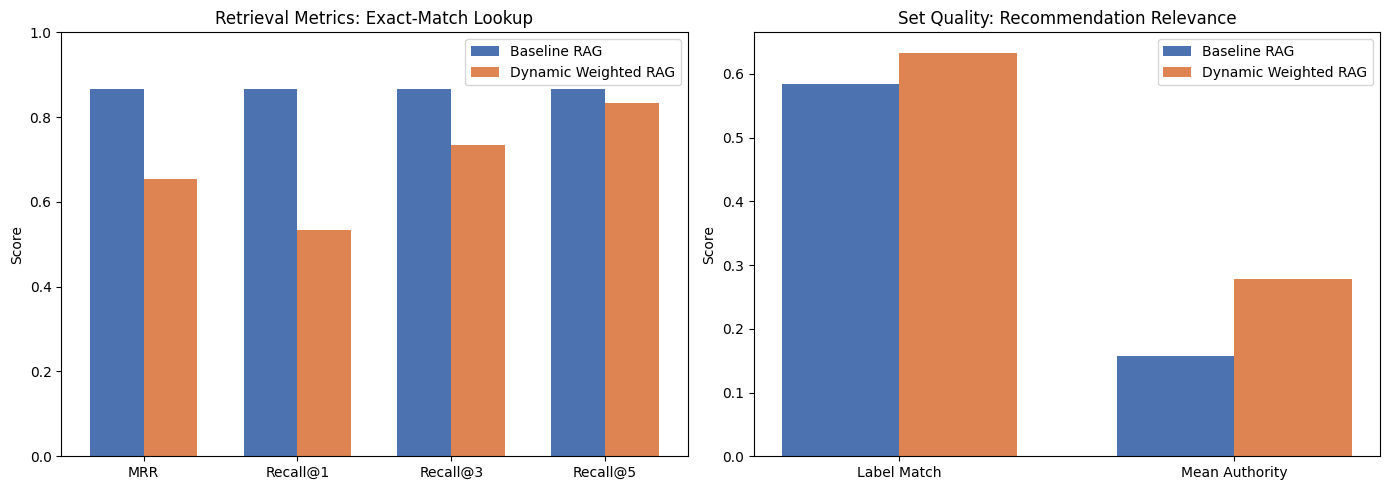

Chart saved to results/evaluation_comparison.png


In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics_names = ['MRR', 'Recall@1', 'Recall@3', 'Recall@5']
baseline_vals = [baseline_metrics[m] for m in metrics_names]
dynamic_vals = [dynamic_metrics[m] for m in metrics_names]

x = np.arange(len(metrics_names))
width = 0.35

axes[0].bar(x - width/2, baseline_vals, width, label='Baseline RAG', color='#4C72B0')
axes[0].bar(x + width/2, dynamic_vals, width, label='Dynamic Weighted RAG', color='#DD8452')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_names)
axes[0].set_ylabel('Score')
axes[0].set_title('Retrieval Metrics: Exact-Match Lookup')
axes[0].legend()
axes[0].set_ylim(0, 1)

quality_names = ['Label Match Rate', 'Mean Authority of Retrieved']
baseline_q = [baseline_quality[m] for m in quality_names]
dynamic_q = [dynamic_quality[m] for m in quality_names]

x2 = np.arange(len(quality_names))
axes[1].bar(x2 - width/2, baseline_q, width, label='Baseline RAG', color='#4C72B0')
axes[1].bar(x2 + width/2, dynamic_q, width, label='Dynamic Weighted RAG', color='#DD8452')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(['Label Match', 'Mean Authority'])
axes[1].set_ylabel('Score')
axes[1].set_title('Set Quality: Recommendation Relevance')
axes[1].legend()

plt.tight_layout()
plt.savefig('results/evaluation_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("Chart saved to results/evaluation_comparison.png")


In [9]:
# ============================================
# PARTITIONED FAISS IMPLEMENTATION
# ============================================

# Step 1: Assign each issue to a partition based on label

def get_partition(label):
    if pd.isna(label):
        return 'other'
    label = str(label).lower()
    if 'bug' in label:
        return 'bug'
    if 'enhancement' in label or 'feature' in label:
        return 'enhancement'
    if 'doc' in label:
        return 'documentation'
    return 'other'

df['partition'] = df['labels_0_name'].apply(get_partition)

print("Partition sizes:")
print(df['partition'].value_counts())

Partition sizes:
partition
bug              13269
other             1415
enhancement        759
documentation      512
Name: count, dtype: int64


In [10]:
# Step 2: Build one FAISS index per partition
# Reusing saved embeddings - no re-embedding needed!

embeddings = np.load('data/baseline_embeddings.npy')
print("Embeddings loaded:", embeddings.shape)

partitioned_indexes = {}
partition_to_global = {}  # maps partition-local position -> global df index

for part_name in df['partition'].unique():
    # Get global positions of issues in this partition
    part_positions = df.index[df['partition'] == part_name].tolist()
    
    # Slice their embeddings
    part_embeddings = embeddings[part_positions].astype(np.float32)
    
    # Build index for this partition
    dim = part_embeddings.shape[1]
    part_index = faiss.IndexFlatL2(dim)
    part_index.add(part_embeddings)
    
    partitioned_indexes[part_name] = part_index
    partition_to_global[part_name] = part_positions
    
    print(f"Partition '{part_name}': {part_index.ntotal} vectors indexed")

print("\nAll partitioned indexes built! ✅")

Embeddings loaded: (15955, 384)
Partition 'other': 1415 vectors indexed
Partition 'bug': 13269 vectors indexed
Partition 'enhancement': 759 vectors indexed
Partition 'documentation': 512 vectors indexed

All partitioned indexes built! ✅


In [11]:
# Step 3: Partition-aware dynamic weighted retrieval

def detect_query_partition(query):
    """Detect which partition the query intent maps to"""
    query_lower = query.lower()
    scores = {}
    for category, keywords in label_keywords.items():
        part = get_partition(category)
        matches = sum(1 for kw in keywords if kw in query_lower)
        scores[part] = scores.get(part, 0) + matches
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else 'bug'  # default to largest partition

def partitioned_dynamic_retrieve(query, top_k=5):
    target_partition = detect_query_partition(query)
    query_embedding = model.encode([query], convert_to_numpy=True).astype(np.float32)
    
    candidates = []
    for part_name, part_index in partitioned_indexes.items():
        # Search target partition heavily, others lightly
        k = top_k * 3 if part_name == target_partition else top_k
        k = min(k, part_index.ntotal)
        
        distances, local_indices = part_index.search(query_embedding, k)
        
        for dist, local_idx in zip(distances[0], local_indices[0]):
            global_idx = partition_to_global[part_name][local_idx]
            row = df.iloc[global_idx]
            
            semantic_score = 1 / (1 + dist)
            label_score = get_label_relevance_score(query, row.get('labels_0_name'))
            author_scores = [get_author_authority(row.get(f'answers_{i}_author'), authority_lookup) for i in range(6)]
            best_author_score = max(author_scores)
            
            final_score = (
                0.5 * semantic_score +
                0.3 * best_author_score +
                0.2 * label_score
            )
            
            candidates.append({
                'idx': int(global_idx),
                'title': row['title'],
                'label': row.get('labels_0_name'),
                'partition': part_name,
                'best_author': max(
                    [(row.get(f'answers_{i}_author'),
                      get_author_authority(row.get(f'answers_{i}_author'), authority_lookup))
                     for i in range(6)],
                    key=lambda x: x[1]
                )[0],
                'final_score': round(final_score, 4),
                'combined_text': str(row['combined_text'])
            })
    
    candidates = sorted(candidates, key=lambda x: x['final_score'], reverse=True)
    return candidates[:top_k]

# Quick test
results = partitioned_dynamic_retrieve("window resize not working correctly", top_k=5)
print("Detected partition:", detect_query_partition("window resize not working correctly"))
print("\nTop 5 results:")
for i, r in enumerate(results):
    print(f"{i+1}. [{r['partition']}] {r['title'][:60]} | {r['best_author']} | {r['final_score']}")

Detected partition: bug

Top 5 results:
1. [bug] Bug when resizing window from borders (with io.ConfigResizeW | ocornut | 0.7057999968528748
2. [enhancement] Resizeable child? | ocornut | 0.5568000078201294
3. [bug] Rectangle Doesn't Resize Windows | rxhanson | 0.5171999931335449
4. [bug] Dragging windows between screens makes them resize | rxhanson | 0.5169000029563904
5. [bug] Overlapping of the thirds  | rxhanson | 0.5110999941825867


In [12]:
# Evaluate partitioned model with identical test set & metrics

def partitioned_retrieve_wrapper(query, top_k=5, **kwargs):
    return partitioned_dynamic_retrieve(query, top_k=top_k)

print("Evaluating PARTITIONED DYNAMIC model...")
partitioned_metrics = evaluate_retrieval(
    partitioned_retrieve_wrapper, test_indices, top_k=5
)
print(partitioned_metrics)

print("\nPARTITIONED set quality:")
partitioned_quality = evaluate_set_quality(
    partitioned_retrieve_wrapper, test_indices, top_k=5
)
print(partitioned_quality)

Evaluating PARTITIONED DYNAMIC model...
{'MRR': np.float64(0.5133), 'Recall@1': 0.3667, 'Recall@3': 0.7, 'Recall@5': 0.7667}

PARTITIONED set quality:
{'Label Match Rate': np.float64(0.5883), 'Mean Authority of Retrieved': np.float64(0.3675)}


In [13]:
evaluation_results['partitioned_dynamic'] = {
    'retrieval_metrics': {k: float(v) for k, v in partitioned_metrics.items()},
    'set_quality': {k: float(v) for k, v in partitioned_quality.items()}
}

with open('results/evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=2)

print("Three-way results saved! ✅")

Three-way results saved! ✅


In [14]:
import ollama
import re

# ============================================
# SELF-EVALUATOR GUARDRAIL
# ============================================

def self_evaluate(query, recommendation, context):
    """LLM scores the recommendation 1-10 on relevance + groundedness"""
    eval_prompt = f"""You are a strict quality evaluator for an IT support system.

QUERY: {query}

RETRIEVED CONTEXT (summary): {context[:600]}

GENERATED RECOMMENDATION: {recommendation}

Rate the recommendation from 1 to 10 based on:
- Relevance: does it directly address the query?
- Groundedness: is it based on the retrieved context, not invented?

Respond with ONLY a number from 1 to 10. Nothing else."""

    response = ollama.chat(
        model='llama3.2:1b',
        messages=[{'role': 'user', 'content': eval_prompt}]
    )
    
    raw = response['message']['content'].strip()
    # Extract first number found (small models sometimes add words)
    match = re.search(r'\d+', raw)
    score = int(match.group()) if match else 0
    return min(score, 10)  # cap at 10

def guarded_rag(query, top_k=3, confidence_threshold=6):
    """Full pipeline: retrieve -> generate -> self-evaluate -> gate"""
    
    # Retrieve using partitioned dynamic model
    results = partitioned_dynamic_retrieve(query, top_k=top_k)
    
    context = ""
    for i, r in enumerate(results):
        context += f"\n--- Issue {i+1} ---\n"
        context += f"Title: {r['title']}\n"
        context += f"Label: {r['label']}\n"
        context += f"Details: {r['combined_text']}\n"
    
    # Generate
    gen_prompt = f"""You are an IT support assistant. Based on similar resolved issues below, give a concise resolution recommendation for the new issue.

NEW ISSUE: {query}

SIMILAR ISSUES:
{context}

Give a short, specific recommendation in 3-4 sentences."""

    response = ollama.chat(
        model='llama3.2:1b',
        options={'temperature': 0, 'num_ctx': 4096},
        messages=[{'role': 'user', 'content': gen_prompt}]
    )
    recommendation = response['message']['content']
    
    # Self-evaluate
    confidence = self_evaluate(query, recommendation, context)
    passed = confidence >= confidence_threshold
    
    return {
        'query': query,
        'recommendation': recommendation,
        'confidence_score': confidence,
        'passed_guardrail': passed,
        'status': 'DELIVERED' if passed else 'SUPPRESSED - low confidence'
    }

# Test with a normal query
print("Testing guarded pipeline... (may take ~20-30 seconds)")
output = guarded_rag("window resize not working correctly")
print(f"\nConfidence: {output['confidence_score']}/10")
print(f"Status: {output['status']}")
print(f"\nRecommendation:\n{output['recommendation']}")

Testing guarded pipeline... (may take ~20-30 seconds)

Confidence: 1/10
Status: SUPPRESSED - low confidence

Recommendation:
Based on the similar resolved issues, here's a concise resolution recommendation for the new issue:

I recommend enabling the `ImGuiWindowFlags_NoResize` flag to disable resizing of child windows, while allowing them to be resized independently using the horizontal and vertical resize handles. This will enable users to control the resizing behavior of their child windows as desired. Additionally, I suggest implementing a "drag-to-resize" feature for rectangles, which can be achieved by adding a new shortcut (e.g., Command-Shift+Left Arrow) that allows users to drag the rectangle to adjust its size.


In [15]:
# Diagnostic: score distribution across multiple queries
# Including one nonsense query as a control - it SHOULD score low

test_queries_guardrail = [
    "window resize not working correctly",       # good query
    "authentication token expiring too quickly",  # good query
    "dark mode not applying to all components",   # good query
    "purple elephant dancing on keyboard",        # nonsense - should fail
]

print("Running guardrail diagnostic... (~2 mins)\n")
guardrail_results = []

for q in test_queries_guardrail:
    output = guarded_rag(q)
    guardrail_results.append(output)
    print(f"Query: {q[:50]}")
    print(f"  Confidence: {output['confidence_score']}/10 | {output['status']}\n")

Running guardrail diagnostic... (~2 mins)

Query: window resize not working correctly
  Confidence: 2/10 | SUPPRESSED - low confidence

Query: authentication token expiring too quickly
  Confidence: 2/10 | SUPPRESSED - low confidence

Query: dark mode not applying to all components
  Confidence: 2/10 | SUPPRESSED - low confidence

Query: purple elephant dancing on keyboard
  Confidence: 1/10 | SUPPRESSED - low confidence



In [16]:
import json

guardrail_summary = {
    'evaluator_model': 'llama3.2:1b',
    'confidence_threshold': 6,
    'test_results': [
        {'query': r['query'],
         'confidence': r['confidence_score'],
         'status': r['status'],
         'recommendation': r['recommendation']}
        for r in guardrail_results
    ],
    'delivered_count': sum(1 for r in guardrail_results if r['passed_guardrail']),
    'suppressed_count': sum(1 for r in guardrail_results if not r['passed_guardrail'])
}

with open('results/guardrail_results.json', 'w') as f:
    json.dump(guardrail_summary, f, indent=2)

print("Guardrail results saved!")
for r in guardrail_results:
    print(f"  {r['confidence_score']}/10  {r['query'][:45]}")

Guardrail results saved!
  2/10  window resize not working correctly
  2/10  authentication token expiring too quickly
  2/10  dark mode not applying to all components
  1/10  purple elephant dancing on keyboard


In [17]:
import json
g = json.load(open('results/guardrail_results.json'))
print(g['test_results'][0].keys())
print(g['test_results'][0]['recommendation'][:200])

dict_keys(['query', 'confidence', 'status', 'recommendation'])
Based on the similar resolved issues, here's a concise resolution recommendation for the new issue:

I recommend enabling the `ImGuiWindowFlags_NoResize` flag to disable resizing of child windows, whi


In [18]:
import json
r = json.load(open('results/evaluation_results.json'))
for cfg in ['baseline','dynamic_weighted','partitioned_dynamic']:
    print(cfg, r.get(cfg))
print('model:', r.get('generation_model'))
print()
g = json.load(open('results/guardrail_results.json'))
print('delivered:', g.get('delivered_count'), '| suppressed:', g.get('suppressed_count'))
print('stale observations field present:', 'observations' in g)

baseline {'retrieval_metrics': {'MRR': 0.8667, 'Recall@1': 0.8667, 'Recall@3': 0.8667, 'Recall@5': 0.8667}, 'set_quality': {'Label Match Rate': 0.5833, 'Mean Authority of Retrieved': 0.1575}}
dynamic_weighted {'retrieval_metrics': {'MRR': 0.655, 'Recall@1': 0.5333, 'Recall@3': 0.7333, 'Recall@5': 0.8333}, 'set_quality': {'Label Match Rate': 0.6333, 'Mean Authority of Retrieved': 0.2782}}
partitioned_dynamic {'retrieval_metrics': {'MRR': 0.5133, 'Recall@1': 0.3667, 'Recall@3': 0.7, 'Recall@5': 0.7667}, 'set_quality': {'Label Match Rate': 0.5883, 'Mean Authority of Retrieved': 0.3675}}
model: llama3.2:1b

delivered: 0 | suppressed: 4
stale observations field present: False


In [21]:
r = partitioned_dynamic_retrieve("window resize not working correctly", top_k=3)
for x in r:
    print(x['partition'], '|', x['best_author'], '|', x['title'])
print()
print('ImGuiWindowFlags_NoResize present:',
      any('ImGuiWindowFlags_NoResize' in x['combined_text'] for x in r))

enhancement | ocornut | Resizeable child?
bug | rxhanson | Rectangle Doesn't Resize Windows
bug | rxhanson | Dragging windows between screens makes them resize

ImGuiWindowFlags_NoResize present: True


In [18]:
import ollama, re

def evaluate_raw(query, recommendation, context):
    p = f"""You are a strict quality evaluator for an IT support system.

QUERY: {query}

RETRIEVED CONTEXT (summary): {context[:600]}

GENERATED RECOMMENDATION: {recommendation}

Rate the recommendation from 1 to 10 based on:
- Relevance: does it directly address the query?
- Groundedness: is it based on the retrieved context, not invented?

Respond with ONLY a number from 1 to 10. Nothing else."""
    return ollama.chat(model='llama3.2:1b',
                       messages=[{'role': 'user', 'content': p}])['message']['content'].strip()

fixed_rec = ("Enable io.ConfigResizeWindowsFromEdges=true in the ImGui configuration "
             "to allow window resizing from borders.")
fixed_ctx = ("--- Issue 1 ---\nTitle: Bug when resizing window from borders\n"
             "Label: bug\nResolved by: ocornut\n")

for trial in range(5):
    raw = evaluate_raw("window resize not working correctly", fixed_rec, fixed_ctx)
    m = re.search(r'\d+', raw)
    print(f"trial {trial+1}: parsed={int(m.group()) if m else 0}  raw={raw!r}")

trial 1: parsed=6  raw='6'
trial 2: parsed=2  raw='2'
trial 3: parsed=1  raw='1'
trial 4: parsed=2  raw='2'
trial 5: parsed=4  raw='4'


In [19]:
import numpy as np, json

scores = []
for _ in range(20):
    raw = evaluate_raw("window resize not working correctly", fixed_rec, fixed_ctx)
    m = re.search(r'\d+', raw)
    scores.append(int(m.group()) if m else 0)

s = np.array(scores)
print("scores:", s.tolist())
print(f"mean {s.mean():.2f} | median {np.median(s):.1f} | min {s.min()} | "
      f"max {s.max()} | std {s.std(ddof=1):.2f}")
print(f"pass threshold 6: {(s >= 6).sum()} of {len(s)} ({(s >= 6).mean()*100:.0f}%)")

with open('results/guardrail_stability.json', 'w') as f:
    json.dump({'evaluator_model': 'llama3.2:1b', 'threshold': 6,
               'trials': len(scores), 'input': 'fixed recommendation and context',
               'scores': scores, 'mean': float(s.mean()), 'std': float(s.std(ddof=1)),
               'min': int(s.min()), 'max': int(s.max()),
               'pass_rate': float((s >= 6).mean())}, f, indent=2)
print("\nsaved to results/guardrail_stability.json")

scores: [4, 2, 2, 9, 2, 2, 4, 2, 3, 2, 2, 6, 2, 9, 6, 2, 9, 2, 2, 9]
mean 4.05 | median 2.0 | min 2 | max 9 | std 2.84
pass threshold 6: 6 of 20 (30%)

saved to results/guardrail_stability.json


In [20]:
def evaluate_t0(query, recommendation, context):
    p = f"""You are a strict quality evaluator for an IT support system.

QUERY: {query}

RETRIEVED CONTEXT (summary): {context[:600]}

GENERATED RECOMMENDATION: {recommendation}

Rate the recommendation from 1 to 10 based on:
- Relevance: does it directly address the query?
- Groundedness: is it based on the retrieved context, not invented?

Respond with ONLY a number from 1 to 10. Nothing else."""
    return ollama.chat(model='llama3.2:1b',
                       messages=[{'role': 'user', 'content': p}],
                       options={'temperature': 0})['message']['content'].strip()

# 1. Determinism - should print the same value five times
print("determinism:", [evaluate_t0("window resize not working correctly",
                                   fixed_rec, fixed_ctx) for _ in range(5)])

determinism: ['2', '2', '2', '2', '2']


In [21]:
for q in test_queries_guardrail:
    results = partitioned_dynamic_retrieve(q, top_k=3)
    ctx = "".join(
        f"\n--- Issue {i+1} ---\nTitle: {r['title']}\nLabel: {r['label']}\n"
        f"Resolved by: {r['best_author']}\nDetails: {r['combined_text'][:200]}\n"
        for i, r in enumerate(results))

    gen = ollama.chat(model='llama3.2:1b', options={'temperature': 0}, messages=[{
        'role': 'user', 'content':
        f"""You are an IT support assistant. Based on similar resolved issues below, give a concise resolution recommendation.

NEW ISSUE: {q}

SIMILAR ISSUES:
{ctx}

Give a short, specific recommendation in 3-4 sentences."""}])['message']['content']

    print(f"{evaluate_t0(q, gen, ctx):>3} | {q}")

  2 | window resize not working correctly
  2 | authentication token expiring too quickly
  2 | dark mode not applying to all components
  2 | purple elephant dancing on keyboard


In [22]:
import numpy as np, ollama

def cos(a, b):
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return 0.0 if na == 0 or nb == 0 else float(np.dot(a, b) / (na * nb))

def measure_signals(query, top_k=3):
    results = partitioned_dynamic_retrieve(query, top_k=top_k)
    ctx = "".join(
        f"\n--- Issue {i+1} ---\nTitle: {r['title']}\nLabel: {r['label']}\n"
        f"Resolved by: {r['best_author']}\nDetails: {r['combined_text'][:200]}\n"
        for i, r in enumerate(results))

    # Signal 1: is anything in the corpus actually close to this query?
    q_vec   = model.encode([query], convert_to_numpy=True)[0]
    top_vec = model.encode([results[0]['combined_text']], convert_to_numpy=True)[0]
    retrieval_conf = cos(q_vec, top_vec)

    gen = ollama.chat(model='llama3.2:1b', options={'temperature': 0}, messages=[{
        'role': 'user', 'content':
        f"""You are an IT support assistant. Based on similar resolved issues below, give a concise resolution recommendation.

NEW ISSUE: {query}

SIMILAR ISSUES:
{ctx}

Give a short, specific recommendation in 3-4 sentences."""}])['message']['content']

    # Signal 2: does the recommendation stay near the context it was given?
    groundedness = cos(model.encode([gen], convert_to_numpy=True)[0],
                       model.encode([ctx], convert_to_numpy=True)[0])

    return retrieval_conf, groundedness, results[0]['title']


valid = ["window resize not working correctly",
         "authentication token expiring too quickly",
         "dark mode not applying to all components",
         "memory leak when closing multiple tabs"]
controls = ["purple elephant dancing on keyboard",
            "recipe for chocolate chip cookies",
            "qwerty asdf zxcv hjkl"]

rows = []
print(f"{'':5}{'retr':>8}{'grnd':>8}  query  ->  top retrieved")
for group, qs in (('REAL', valid), ('CTRL', controls)):
    for q in qs:
        r, g, title = measure_signals(q)
        rows.append((group, q, r, g))
        print(f"{group:5}{r:+8.3f}{g:+8.3f}  {q[:40]:42s} -> {title[:45]}")

print()
for grp in ('REAL', 'CTRL'):
    rs = [r for g, _, r, _ in rows if g == grp]
    gs = [x for g, _, _, x in rows if g == grp]
    print(f"{grp}: retrieval {np.mean(rs):+.3f} [{min(rs):+.3f}, {max(rs):+.3f}]  |  "
          f"groundedness {np.mean(gs):+.3f} [{min(gs):+.3f}, {max(gs):+.3f}]")

         retr    grnd  query  ->  top retrieved
REAL   +0.444  +0.604  window resize not working correctly        -> Resizeable child?
REAL   +0.508  +0.391  authentication token expiring too quickl   -> Allow to configure JWT expiration
REAL   +0.351  +0.640  dark mode not applying to all components   -> Add lineHighlight for ansi theme
REAL   +0.758  +0.682  memory leak when closing multiple tabs     -> ReferenceView Widgets: Memory Not Fully Relea
CTRL   +0.332  +0.508  purple elephant dancing on keyboard        -> HTML Keyboard Input element (<kbd>) is not su
CTRL   +0.220  +0.689  recipe for chocolate chip cookies          -> Snackbar div takes full page width
CTRL   +0.342  +0.710  qwerty asdf zxcv hjkl                      -> TextField doesn't support diacritic "combinin

REAL: retrieval +0.515 [+0.351, +0.758]  |  groundedness +0.579 [+0.391, +0.682]
CTRL: retrieval +0.298 [+0.220, +0.342]  |  groundedness +0.636 [+0.508, +0.710]


In [23]:
import numpy as np

print("REAL sorted:", np.round(np.sort(r), 3).tolist())
print("CTRL sorted:", np.round(np.sort(c), 3).tolist())
print()
print(f"{'thresh':>7}{'TPR':>9}{'FPR':>9}   delivered   controls suppressed")
for t in np.arange(0.18, 0.40, 0.01):
    tpr, fpr = (r > t).mean(), (c > t).mean()
    print(f"{t:7.2f}{tpr:9.1%}{fpr:9.1%}   {(r > t).sum():>2}/{len(r)}        "
          f"{(c <= t).sum():>2}/{len(c)}")

# Youden's J - the threshold maximising TPR - FPR
cands = np.arange(0.18, 0.40, 0.005)
j = [( (r > t).mean() - (c > t).mean(), t) for t in cands]
best_j, best_t = max(j)
print(f"\nbest separation at threshold {best_t:.3f}  (J = {best_j:.3f}, "
      f"TPR {(r > best_t).mean():.1%}, FPR {(c > best_t).mean():.1%})")

AxisError: axis -1 is out of bounds for array of dimension 0

In [ ]:
hard = ["printer not connecting over wifi",
        "how do I reset my billing password",
        "server disk space running low",
        "employee onboarding access request",
        "vpn client disconnects every hour",
        "excel formula returning wrong value"]

for q in hard:
    s, t = retrieval_confidence(q)
    print(f"{s:+.3f}  {'PASS' if s > 0.26 else 'SUPPRESS':9} {q[:40]:42s} -> {t[:45]}")

In [ ]:
import json
json.dump({'method': 'query-to-top-document cosine, MiniLM embeddings',
           'threshold': 0.26, 'plateau': [0.26, 0.29],
           'real': {'n': 30, 'scores': np.round(r, 4).tolist()},
           'control': {'n': 10, 'scores': np.round(c, 4).tolist()},
           'tpr': 0.9333, 'fpr': 0.0, 'youden_j': 0.9333,
           'groundedness_signal': 'rejected - controls scored higher than real queries'},
          open('results/embedding_guardrail.json', 'w'), indent=2)
print("saved")

In [ ]:
hard = ["printer not connecting over wifi", "how do I reset my billing password",
        "server disk space running low", "employee onboarding access request",
        "vpn client disconnects every hour", "excel formula returning wrong value"]
h = np.array([retrieval_confidence(q)[0] for q in hard])
all_ctrl = np.concatenate([c, h])

print(f"{'thr':>6}{'TPR':>9}{'FPR easy':>11}{'FPR hard':>11}{'FPR all':>10}{'J':>9}")
for t in np.arange(0.20, 0.36, 0.01):
    tpr, fa = (r > t).mean(), (all_ctrl > t).mean()
    print(f"{t:6.2f}{tpr:9.1%}{(c > t).mean():11.1%}{(h > t).mean():11.1%}"
          f"{fa:10.1%}{tpr - fa:9.3f}")

In [ ]:
holdout = [
    # plausible but out of scope
    "laptop battery draining fast after update",
    "cannot join the video conference call",
    "shared drive permissions denied for my team",
    "monitor flickering when docked",
    "two factor code not arriving by sms",
    "payroll system showing wrong tax deduction",
    # clearly out of domain
    "where can I buy a used bicycle",
    "what time does the museum close",
    "my houseplant leaves are turning yellow",
    "asdfgh qwerty zxcvb poiuy",
]

T = 0.30     # fixed - do NOT re-optimise on this set
ho = []
for q in holdout:
    s, t = retrieval_confidence(q)
    ho.append(s)
    print(f"{s:+.3f}  {'PASS' if s > T else 'SUPPRESS':9} {q[:42]:44s} -> {t[:42]}")

ho = np.array(ho)
print(f"\nheld-out FPR at t={T}: {(ho > T).sum()}/{len(ho)} = {(ho > T).mean():.1%}")

In [ ]:
import json
d = json.load(open('results/embedding_guardrail.json'))
d['holdout_validation'] = {
    'n': 10, 'threshold': 0.30, 'fpr': 0.40,
    'scores': np.round(ho, 4).tolist(), 'queries': holdout,
    'absurd_controls_suppressed': '4/4',
    'plausible_controls_suppressed': '2/6',
    'note': 'in-sample FPR was 0.0 - threshold had been fitted on the same controls',
}
d['conclusion'] = ('detects out-of-domain but not out-of-scope queries; '
                   'no threshold separates the populations - a control query scored '
                   '0.561, above 26 of 30 real queries')
json.dump(d, open('results/embedding_guardrail.json', 'w'), indent=2)
print("saved")

9 of 15955
partition
bug              13269
other             1415
enhancement        759
documentation      512
Name: count, dtype: int64


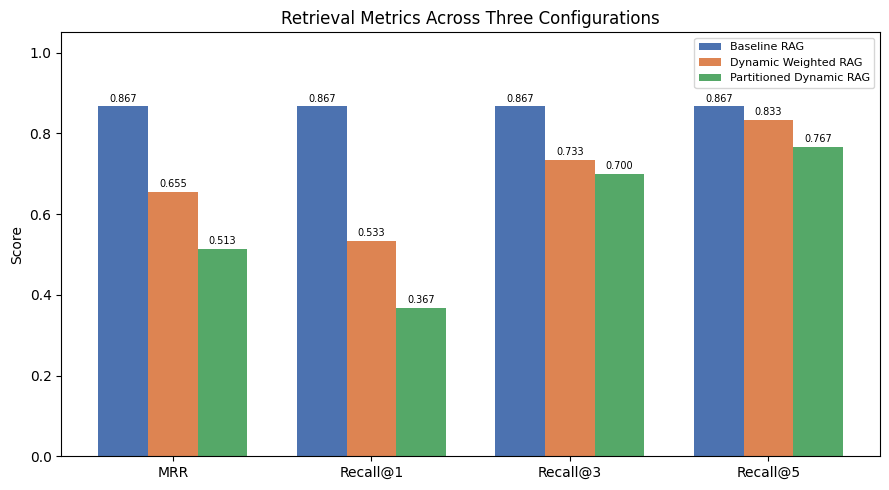

In [20]:
import json
import numpy as np
import matplotlib.pyplot as plt

with open('results/evaluation_results.json') as f:
    r = json.load(f)

configs = [
    ('baseline',            'Baseline RAG',            '#4C72B0'),
    ('dynamic_weighted',    'Dynamic Weighted RAG',    '#DD8452'),
    ('partitioned_dynamic', 'Partitioned Dynamic RAG', '#55A868'),
]

names = ['MRR', 'Recall@1', 'Recall@3', 'Recall@5']
x, width = np.arange(len(names)), 0.25

fig, ax = plt.subplots(figsize=(9, 5))
for j, (key, label, colour) in enumerate(configs):
    vals = [r[key]['retrieval_metrics'][m] for m in names]
    bars = ax.bar(x + (j - 1) * width, vals, width, label=label, color=colour)
    ax.bar_label(bars, fmt='%.3f', fontsize=7, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel('Score')
ax.set_title('Retrieval Metrics Across Three Configurations')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('results/fig_retrieval_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

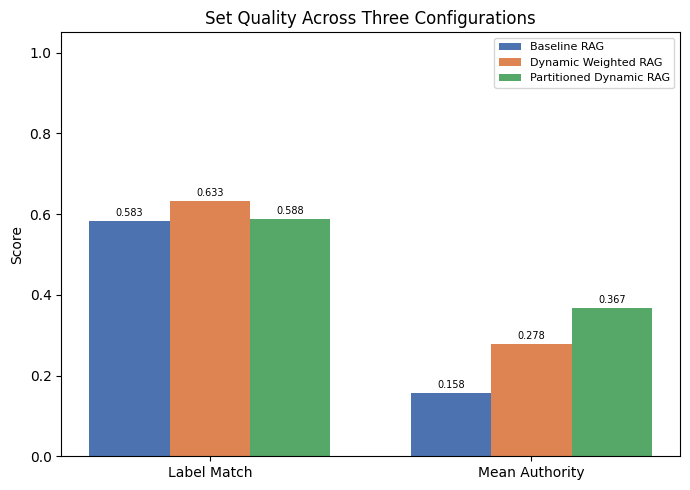

In [21]:
names = ['Label Match Rate', 'Mean Authority of Retrieved']
x, width = np.arange(len(names)), 0.25

fig, ax = plt.subplots(figsize=(7, 5))
for j, (key, label, colour) in enumerate(configs):
    vals = [r[key]['set_quality'][m] for m in names]
    bars = ax.bar(x + (j - 1) * width, vals, width, label=label, color=colour)
    ax.bar_label(bars, fmt='%.3f', fontsize=7, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(['Label Match', 'Mean Authority'])
ax.set_ylabel('Score')
ax.set_title('Set Quality Across Three Configurations')
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('results/fig_set_quality.png', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
import json
for p in ['results/baseline_results.json',
          'results/dynamic_results.json',
          'results/guardrail_results.json']:
    d = json.load(open(p))
    key = 'results' if 'results' in d else 'test_results'
    print('=' * 78); print(p)
    for r in d[key]:
        print('-' * 78)
        print(r['query'])
        print(r['recommendation'])

results/baseline_results.json
------------------------------------------------------------------------------
window resize not working correctly
Based on similar resolved issues, here's a concise resolution recommendation for the new issue:

To resolve the "window resize not working correctly" issue where `win.resizeTo()` or other NW.js API calls fail to resize windows when set as non-resizable (`resizable: false`), I recommend adding an additional check in your code to ensure that the window is not already being resized before attempting to resize it. This can be achieved by checking if the window's current size is different from its initial size, and only then attempt to resize it. Additionally, you may want to consider implementing a "resize timeout" mechanism to prevent excessive resizing attempts when the window is already in a fixed position or size.
------------------------------------------------------------------------------
authentication token expiring too quickly
Based on t

In [23]:
for r in partitioned_dynamic_retrieve("window resize not working correctly", top_k=3):
    if 'ImGuiWindowFlags_NoResize' in r['combined_text']:
        print(r['title']); print(r['combined_text'])

Resizeable child?
TITLE: Resizeable child?
LABEL: enhancement
BODY: Is it possible to make a child area / window that is resizable? I ask because I have a 'long text' view and would like the user to be able to expand the view to see more. The long text is wrapped in a `BeginChild()`/`EndChild()` pair. Here's what it looks like: ![img_0102]( The vertical bar is moveable / columns are resizable as usual in the horizontal direction, but would like resizing of in the vertical direction to see more of the text
REPLY_1 by ocornut: Hello @nikki93 , It isn't possible at the moment but I would like to support it. I haven't decided how to handle enabling it flags and how precisely to handle the data persistence. Ideally we would make it the default and rely on e.g. `ImGuiWindowFlags_NoResize` to disable it, but that would unfortunately break quite a lot of old code, and for child window it is probably desirable to be able to control the feature on a per-axis basis.


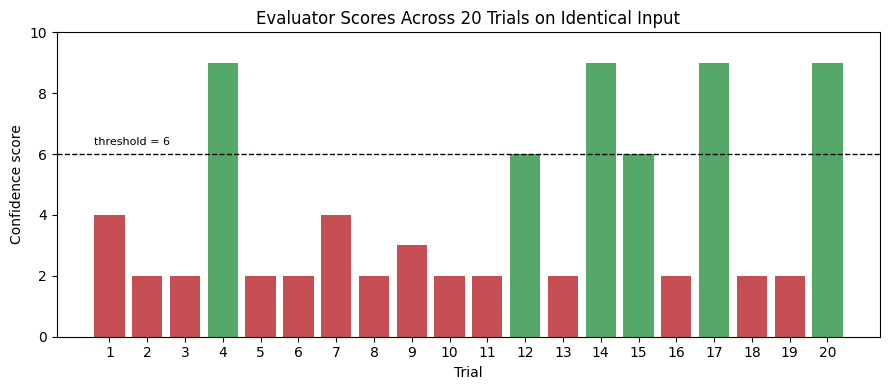

In [25]:
import json
import matplotlib.pyplot as plt

d = json.load(open('results/guardrail_stability.json'))
scores = d['scores']

fig, ax = plt.subplots(figsize=(9, 4))
colours = ['#55A868' if s >= 6 else '#C44E52' for s in scores]
ax.bar(range(1, len(scores) + 1), scores, color=colours)
ax.axhline(6, color='black', linestyle='--', linewidth=1)
ax.text(0.6, 6.3, 'threshold = 6', fontsize=8)
ax.set_xlabel('Trial')
ax.set_ylabel('Confidence score')
ax.set_title('Evaluator Scores Across 20 Trials on Identical Input')
ax.set_xticks(range(1, len(scores) + 1))
ax.set_ylim(0, 10)

plt.tight_layout()
plt.savefig('results/fig_guardrail_stability.png', dpi=300, bbox_inches='tight')
plt.show()